## **tools**

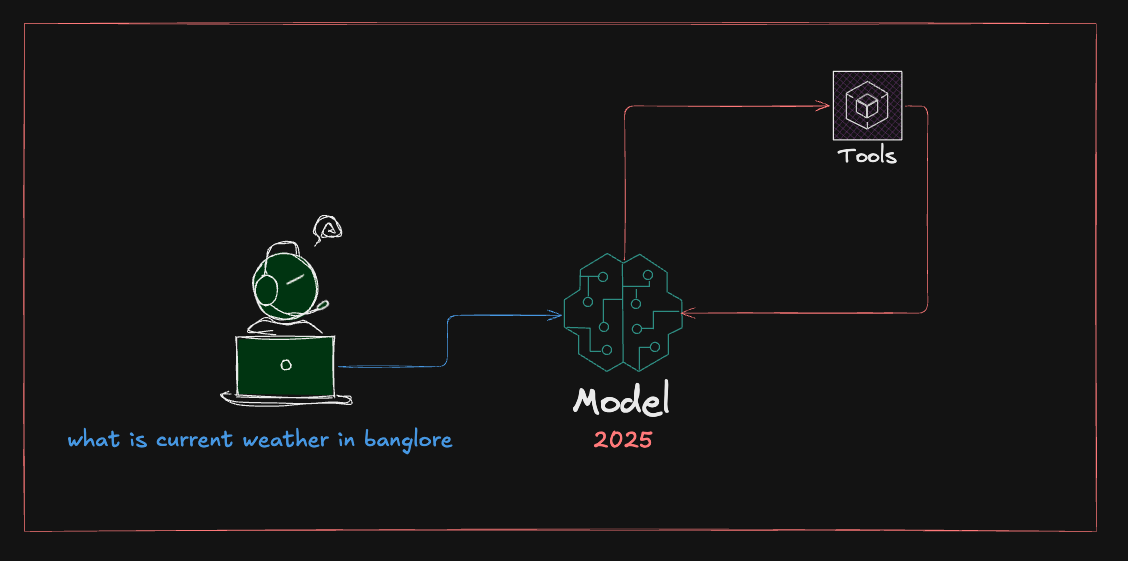

### Tools
Models can request to call tools that perform tasks such as fetching data from a database, searching the web, or running code. Tools are pairings of:
1. A schema, including the name of the tool, a description, and/or argument definitions (often a JSON schema)
2. A function or coroutine to execute.

In [1]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")



In [9]:
from langchain.chat_models import init_chat_model
model = init_chat_model("groq:openai/gpt-oss-120b")
groq_response = model.invoke("Write a poem about the beauty of nature in 2 lines.")
print(groq_response.content)

Verdant hills breathe whispers of sunrise, while rivers stitch silver threads through emerald dreams.  
Stars drape the night in velvet hush, and every leaf sings the earth’s eternal hymn.


In [10]:
def weather(location: str) -> str:
    """ 
    Getting the weather at specified location
    """

    return f"its sunny in {location}"

In [11]:
from langchain.agents import create_agent

agent = create_agent(
    model = model,
    tools = [weather],
    system_prompt= "you are a helpfull assitant"
)



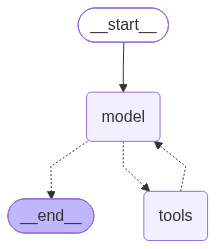

In [12]:
agent

In [13]:
response = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "what is the weather in bengluru"
            }
        ]
    }
)

In [16]:
response["messages"][-1].content

'The current weather in Bengaluru is sunny. Enjoy the clear skies!'

In [18]:
from langchain.tools import tool

@tool
def weather(location: str) -> str:
    """ 
    Getting the weather at specified location
    """

    return f"its sunny in {location}"

In [19]:
model_with_tool = model.bind_tools([weather])

In [20]:
response = model_with_tool.invoke("what is weather in bengaluru")

In [21]:
response

AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "what is weather in bengaluru". We need to get current weather. Use function weather with location "Bengaluru".', 'tool_calls': [{'id': 'fc_1a399217-d13f-4c99-8115-a19e93c1dc07', 'function': {'arguments': '{"location":"Bengaluru"}', 'name': 'weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 61, 'prompt_tokens': 126, 'total_tokens': 187, 'completion_time': 0.128504475, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.006961071, 'prompt_tokens_details': None, 'queue_time': 0.368906797, 'total_time': 0.135465546}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_19b184c447', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1caea-f099-7601-bf84-e326867524cb-0', tool_calls=[{'name': 'weather', 'args': {'location': 'Bengaluru'}, 'id': 'fc_1a399217-d13f-4c99-8115-a19e93c

In [22]:
for tool_call in response.tool_calls:
    print(f"Tool: {tool_call["name"]}")
    print(f"Arg: {tool_call['args']}")

Tool: weather
Arg: {'location': 'Bengaluru'}


# **Middlewares** 

In [23]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage, SystemMessage

In [24]:
from email import message


llm = init_chat_model("groq:openai/gpt-oss-120b")

agent = create_agent(
    model=llm,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model = llm,
            trigger =("messages",10),
            keep = ("messages",4),
        )
    ]
)

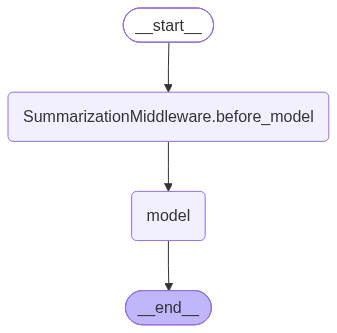

In [25]:
agent

In [26]:
### Run with thread id
config={"configurable":{"thread_id":"test-1"}}

In [27]:
# Alternative test data
questions = [
    "What is 2+2?",
    "What is 10*5?",
    "What is 100/4?",
    "What is 15-7?",
    "What is 3*3?",
    "What is 4*4?",
]


for q in questions:
    response=agent.invoke({"messages":[HumanMessage(content=q)]},config)
    print(f"Messages: {response}")
    print(f"Messages: {len(response['messages'])}")

Messages: {'messages': [HumanMessage(content='What is 2+2?', additional_kwargs={}, response_metadata={}, id='2d467f08-9ffe-405f-9c91-a5ff7b16ee51'), AIMessage(content='2\u202f+\u202f2\u202f=\u202f4.', additional_kwargs={'reasoning_content': 'The user asks a simple math question. The answer is 4. No policy issues. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 78, 'total_tokens': 119, 'completion_time': 0.086297501, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.01571558, 'prompt_tokens_details': None, 'queue_time': 0.165724519, 'total_time': 0.102013081}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_27194a498a', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1cb00-a799-7272-8da1-2623efbde568-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 78, 'output_tokens': 41, 'total_tokens': 119, 'output_token_detail

## **TokenSize**

In [32]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool

@tool
def search_hotel(city: str) -> str:
    """ 
    search nearest hotesl for given location and long response to use more tokens..

    """
    return f"""Hotels in {city}:
    1. Grand Hotel - 5 star, $350/night, spa, pool, gym
    2. City Inn - 4 star, $180/night, business center
    3. Budget Stay - 3 star, $75/night, free wifi"""

llm = init_chat_model("groq:openai/gpt-oss-120b")

agent = create_agent(
    model=llm,
    tools = [search_hotel],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model = llm,
            trigger =("tokens",400),
            keep = ("tokens",200),
        )
    ]
)

### Run with thread id
config={"configurable":{"thread_id":"test-1"}}

def count_tokens(message):
    total_char = sum(len(str(m.content)) for m in message)
    return total_char // 4 ## am consider approx token for 4 chrs= 1 token

In [33]:
cities = ["Bengaluru","Delhi","Hyderbad","Tokyo","Singapore"]

for city in cities:
    response = agent.invoke(
        {"messages": [HumanMessage(content=f"Find hotels in {city}")]},
        config=config
    )

    tokens = count_tokens(response["messages"])
    print(f"{city}: ~{tokens} tokens, {len(response['messages'])} messages")
    print(f"{(response['messages'])}")


Bengaluru: ~1162 tokens, 4 messages
[HumanMessage(content='Find hotels in Bengaluru', additional_kwargs={}, response_metadata={}, id='ef21c338-f84c-4e0d-a43a-e6c4fa2960c9'), AIMessage(content='', additional_kwargs={'reasoning_content': 'User wants hotels in Bengaluru. We can use the search_hotel function. Probably need to pass city "Bengaluru". Let\'s call it.', 'tool_calls': [{'id': 'fc_c6b585b4-c5b4-402c-8c83-56d5b0d63172', 'function': {'arguments': '{"city":"Bengaluru"}', 'name': 'search_hotel'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 62, 'prompt_tokens': 134, 'total_tokens': 196, 'completion_time': 0.129609083, 'completion_tokens_details': {'reasoning_tokens': 31}, 'prompt_time': 0.00507809, 'prompt_tokens_details': None, 'queue_time': 0.158669318, 'total_time': 0.134687173}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_69334c0be3', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider